# Klasifikasi Hewan (Kucing vs Anjing) Menggunakan K-Nearest Neighbors (KNN)
---

## 1. BUSINESS UNDERSTANDING — KLASIFIKASI HEWAN (KUCING VS ANJING)

### 1.1 Latar Belakang, Masalah, dan Solusi
* **Latar Belakang**: Sebuah penangkaran hewan dan klinik veteriner menangani registrasi harian untuk berbagai hewan peliharaan yang baru masuk ke fasilitas mereka. Setiap hewan yang datang diukur parameter morfologi tubuhnya, meliputi tinggi badan, berat badan, panjang tubuh, panjang bulu, ukuran telapak kaki, dan bentuk telinga.
* **Masalah**: Proses identifikasi dan pencatatan klasifikasi hewan secara manual oleh staf pemula sering memakan waktu dan rentan mengalami kesalahan pencatatan (terutama pada hewan berukuran sedang yang memiliki kemiripan tinggi dan berat badan antara kucing dewasa besar dan anjing ras kecil/sedang).
* **Solusi & Tujuan**: Membangun model menggunakan algoritma **K-Nearest Neighbors (KNN)** yang memanfaatkan kemiripan jarak spasial dari keenam ciri fisik untuk mengklasifikasikan jenis hewan (*Kucing* atau *Anjing*) secara otomatis, cepat, dan objektif.

### 1.2 Deskripsi Variabel Dataset (`cat_dog_classifier.csv`)
| Nama Kolom | Jenis Variabel | Tipe Data |
| :--- | :---: | :---: |
| **`Height`** | Fitur Numerik ($x_1$) | `int64` |
| **`Weight`** | Fitur Numerik ($x_2$) | `int64` |
| **`Length`** | Fitur Numerik ($x_3$) | `int64` |
| **`FurLength`** | Fitur Kategorikal ($x_4$) | `object` |
| **`PawSize`** | Fitur Kategorikal ($x_5$) | `object` |
| **`EarShape`** | Fitur Kategorikal ($x_6$) | `object` |
| **`Animal`** | Target ($y$) | `object` |

---

## 2. DATA PREPARATION

### 2.1 Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Pemuatan Dataset

In [2]:
df = pd.read_csv('cat_dog_classifier.csv', sep=';')

### 2.3 Menampilkan Sampel Data

In [3]:
df.head()

,Height,Weight,Length,FurLength,PawSize,EarShape,Animal
0,25,4,30,Short,Small,Round,Cat
1,32,6,38,Medium,Medium,Triangular,Cat
2,38,8,45,Long,Large,Medium,Dog
3,28,5,35,Short,Small,Round,Cat
4,35,7,42,Medium,Medium,Triangular,Dog


### 2.4 Pemeriksaan Dimensi, Ukuran Elemen, Missing Value, dan Duplikasi

In [4]:
print("Dimensi Data (shape) :", df.shape)
print("Total Elemen Data (size) :", df.size)
print("\n--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\nJumlah Baris Duplikat:", df.duplicated().sum())

Dimensi Data (shape) : (49, 7)
Total Elemen Data (size) : 343

--- Jumlah Missing Value per Kolom ---
Height       0
Weight       0
Length       0
FurLength    0
PawSize      0
EarShape     0
Animal       0
dtype: int64

Jumlah Baris Duplikat: 9


### 2.5 Memeriksa Struktur dan Tipe Data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Height     49 non-null     int64
 1   Weight     49 non-null     int64
 2   Length     49 non-null     int64
 3   FurLength  49 non-null     str  
 4   PawSize    49 non-null     str  
 5   EarShape   49 non-null     str  
 6   Animal     49 non-null     str  
dtypes: int64(3), str(4)
memory usage: 2.8 KB


### 2.6 Menampilkan Tabel Nilai Unik pada Masing-Masing Kolom

In [6]:
keterangan = [
    {
        'Nama Kolom': 'Height',
        'Unik': df['Height'].nunique(),
    },
    {
        'Nama Kolom': 'Weight',
        'Unik': df['Weight'].nunique(),
    },
    {
        'Nama Kolom': 'Length',
        'Unik': df['Length'].nunique(),
    },
    {
        'Nama Kolom': 'FurLength',
        'Unik': df['FurLength'].nunique(),
    },
    {
        'Nama Kolom': 'PawSize',
        'Unik': df['PawSize'].nunique(),
    },
    {
        'Nama Kolom': 'EarShape',
        'Unik': df['EarShape'].nunique(),
    },
    {
        'Nama Kolom': 'Animal',
        'Unik': df['Animal'].nunique(),
    }
]

pd.DataFrame(keterangan)

,Nama Kolom,Unik
0,Height,20
1,Weight,15
2,Length,22
3,FurLength,3
4,PawSize,3
5,EarShape,3
6,Animal,3


---

## 3. EXPLORATORY DATA ANALYSIS (EDA)

### 3.1 Statistik Deskriptif & Analisis Outlier (Boxplot, IQR, dan Z-Score)
Menghitung ukuran statistik fitur numerik (`Height`, `Weight`, `Length`) serta mendeteksi pencilan menggunakan metode **Interquartile Range (IQR)** dengan batas $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$ dan metode **Z-Score** dengan kriteria $|z| > 3$.

In [7]:
eda_outliers = []
for col in ['Height', 'Weight', 'Length']:
    q1 = df[col].quantile(0.25)
    med = df[col].median()
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    out_iqr = df[(df[col] < low) | (df[col] > high)]
    
    mean = df[col].mean()
    std = df[col].std()
    z = (df[col] - mean) / std
    out_z = df[np.abs(z) > 3]
    
    eda_outliers.append({
        'Fitur Numerik': f"{col} ({'cm' if col != 'Weight' else 'kg'})",
        'Mean': f"{mean:.2f}",
        'Std Dev': f"{std:.2f}",
        'Min': f"{df[col].min():.2f}",
        'Q1 (25%)': f"{q1:.2f}",
        'Median': f"{med:.2f}",
        'Q3 (75%)': f"{q3:.2f}",
        'Max': f"{df[col].max():.2f}",
        'Batas IQR [Bawah, Atas]': f"[{low:.2f}, {high:.2f}]",
        'Outlier (IQR / Z)': f"{len(out_iqr)} / {len(out_z)}"
    })

pd.DataFrame(eda_outliers)

,Fitur Numerik,Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,"Batas IQR [Bawah, Atas]",Outlier (IQR / Z)
0,Height (cm),34.51,8.24,25.00,30.00,32.00,36.00,65.00,"[21.00, 45.00]",4 / 2
1,Weight (kg),9.39,6.44,4.00,6.00,7.00,10.00,35.00,"[0.00, 16.00]",5 / 2
2,Length (cm),44.61,17.16,30.00,36.00,40.00,43.00,110.00,"[25.50, 53.50]",7 / 2


### 3.2 Visualisasi Distribusi Kelas, Boxplot Outlier & Scatter Plot Morfologi 

C:\Users\notebook\AppData\Local\Temp\ipykernel_7308\1764079785.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Height (cm)', 'Weight (kg)', 'Length (cm)'])


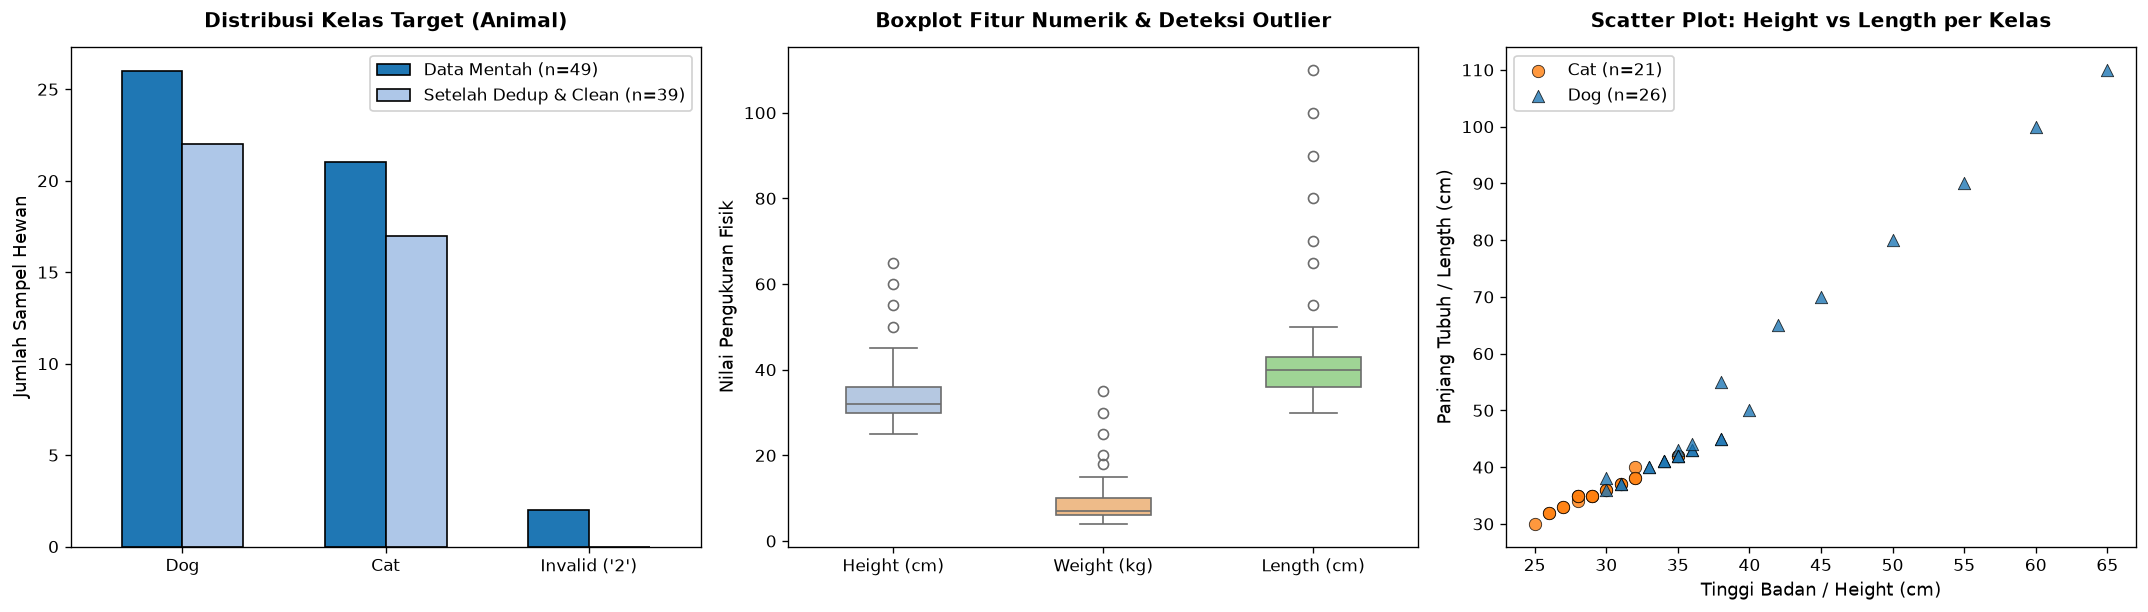

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

df_valid_clean = df[df['Animal'].isin(['Cat', 'Dog'])].drop_duplicates().reset_index(drop=True)
count_raw = df['Animal'].value_counts()
count_clean = df_valid_clean['Animal'].value_counts()

df_prop = pd.DataFrame({
    'Data Mentah (n=49)': [count_raw.get('Dog', 0), count_raw.get('Cat', 0), count_raw.get('2', 0)],
    'Setelah Dedup & Clean (n=39)': [count_clean.get('Dog', 0), count_clean.get('Cat', 0), 0]
}, index=['Dog', 'Cat', "Invalid ('2')"])

df_prop.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#aec7e8'], edgecolor='black', width=0.6)
axes[0].set_title('Distribusi Kelas Target (Animal)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Jumlah Sampel Hewan', fontsize=11)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

sns.boxplot(data=df[['Height', 'Weight', 'Length']], ax=axes[1], palette=['#aec7e8', '#ffbb78', '#98df8a'], width=0.45)
axes[1].set_title('Boxplot Fitur Numerik & Deteksi Outlier', fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel('Nilai Pengukuran Fisik', fontsize=11)
axes[1].set_xticklabels(['Height (cm)', 'Weight (kg)', 'Length (cm)'])

palette_anim = {'Cat': '#ff7f0e', 'Dog': '#1f77b4'}
for anim, color in palette_anim.items():
    subset = df[df['Animal'] == anim]
    marker = 'o' if anim == 'Cat' else '^'
    axes[2].scatter(subset['Height'], subset['Length'], color=color, s=55, alpha=0.8,
                    marker=marker, edgecolor='black', linewidth=0.5, label=f"{anim} (n={len(subset)})")
axes[2].set_title('Scatter Plot: Height vs Length per Kelas', fontsize=12, fontweight='bold', pad=12)
axes[2].set_xlabel('Tinggi Badan / Height (cm)', fontsize=11)
axes[2].set_ylabel('Panjang Tubuh / Length (cm)', fontsize=11)
axes[2].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### 3.3 Analisis Korelasi & Pola Fitur Kategorikal terhadap Target (Gambar 2 di PDF)
Menampilkan Gambar 2:
* (Kiri) Heatmap Korelasi Pearson antara seluruh 6 fitur morfologi dan target `Animal` setelah konversi ordinal.
* (Kanan) Stacked bar chart proporsi kelas berdasarkan `FurLength` & `PawSize` yang membuktikan bahwa kategori *Short/Small* didominasi oleh Kucing (91%), sedangkan *Long/Large* 100% merupakan Anjing.

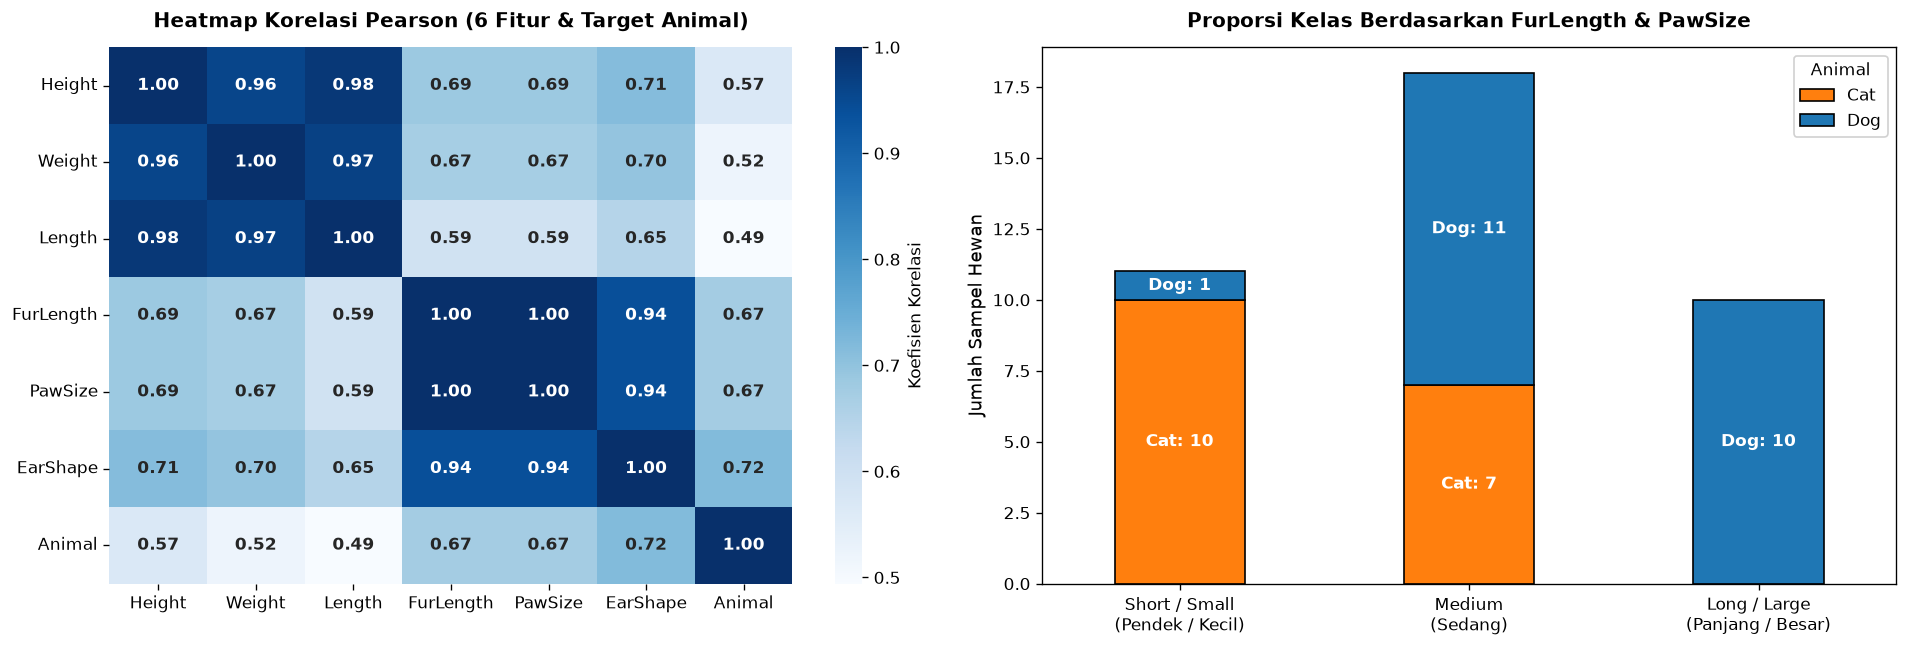

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

df_corr = df_valid_clean.copy()
df_corr['FurLength'] = df_corr['FurLength'].map({'Short': 0, 'Medium': 1, 'Long': 2})
df_corr['PawSize'] = df_corr['PawSize'].map({'Small': 0, 'Medium': 1, 'Large': 2})
df_corr['EarShape'] = df_corr['EarShape'].map({'Round': 0, 'Triangular': 1, 'Medium': 2})
df_corr['Animal'] = df_corr['Animal'].map({'Cat': 0, 'Dog': 1})

corr_matrix = df_corr.corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', ax=axes[0],
            cbar_kws={'label': 'Koefisien Korelasi'}, annot_kws={'size': 10, 'weight': 'bold'})
axes[0].set_title('Heatmap Korelasi Pearson (6 Fitur & Target Animal)', fontsize=12, fontweight='bold', pad=12)

ct = pd.crosstab(df_valid_clean['FurLength'], df_valid_clean['Animal'])[['Cat', 'Dog']]
ct = ct.reindex(['Short', 'Medium', 'Long'])
ct.index = ['Short / Small\n(Pendek / Kecil)', 'Medium\n(Sedang)', 'Long / Large\n(Panjang / Besar)']
ct.plot(kind='bar', stacked=True, ax=axes[1], color=['#ff7f0e', '#1f77b4'], edgecolor='black', width=0.45)

for i, total in enumerate(ct.sum(axis=1)):
    cat_val = ct.iloc[i]['Cat']
    dog_val = ct.iloc[i]['Dog']
    if cat_val > 0:
        axes[1].text(i, cat_val/2, f"Cat: {cat_val}", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    if dog_val > 0:
        axes[1].text(i, cat_val + dog_val/2, f"Dog: {dog_val}", ha='center', va='center', color='white', fontweight='bold', fontsize=10)

axes[1].set_title('Proporsi Kelas Berdasarkan FurLength & PawSize', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('')
axes[1].set_ylabel('Jumlah Sampel Hewan', fontsize=11)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Animal', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### 3.4 Temuan Kunci Analisis EDA
1. **Pemisahan Sempurna pada Kategori Ekstrem**: Pada data bersih ($n = 39$), kolom `FurLength` dan `PawSize` memiliki pola yang berhimpit sempurna ($r = 1.00$): seluruh hewan berbulu panjang dan bertapak kaki besar (*Long / Large*, 10 sampel) adalah **100% Dog (Anjing)**, sedangkan hewan berbulu pendek dan bertapak kecil (*Short / Small*, 11 sampel) adalah **90.9% Cat (Kucing)** (10 Kucing dan hanya 1 Anjing kecil).
2. **Zona Tumpang Tindih (Overlap) pada Kategori Medium**: Tantangan klasifikasi berada pada kelompok `FurLength = Medium` dan `PawSize = Medium` (18 sampel: 12 Dog dan 6 Cat), di mana algoritma KNN mengandalkan kombinasi jarak dari `Height` ($r = +0.57$), `Weight` ($r = +0.52$), `Length` ($r = +0.49$), dan `EarShape` ($r = +0.72$) untuk membedakan anjing dan kucing berukuran sedang.
3. **Outlier Anjing Ras Besar**: Terdeteksi pencilan pada `Height` (4 outlier: 50–65 cm), `Weight` (5 outlier: 18–35 kg), dan `Length` (7 outlier: 55–110 cm) yang seluruhnya merupakan anjing ras besar valid secara biologis.

## 4. DATA PREPROCESSING — PEMBERSIHAN, ENCODING, SCALING & STRATIFIED SPLIT

Mengikuti karakteristik algoritma KNN yang sangat sensitif terhadap perbedaan skala jarak, tahapan Data Preprocessing dilakukan secara sistematis:
1. **Pembersihan Baris Tidak Valid & Duplikat**:
   * Menghapus baris dengan label target tidak valid (`df = df[df['Animal'].isin(['Cat', 'Dog'])]`).
   * Menghapus baris duplikat eksak (`df.drop_duplicates()` $\rightarrow$ 39 baris).
   * Mereduksi duplikasi subset fitur untuk menghilangkan konflik label identik (`df.drop_duplicates(subset=feat_cols, keep='first')` $\rightarrow$ 38 baris bebas konflik).
2. **Konversi Tipe Data Kategorikal ke Numerik (Ordinal Mapping)**:
   * `FurLength`: `{'Short': 0, 'Medium': 1, 'Long': 2}`
   * `PawSize`: `{'Small': 0, 'Medium': 1, 'Large': 2}`
   * `EarShape`: `{'Round': 0, 'Triangular': 1, 'Medium': 2}`
   * `Animal`: `{'Cat': 0, 'Dog': 1}`
3. **Stratified Train-Test Split (80% : 20%, `random_state=42`)**:
   Untuk dataset klasifikasi biner, pembagian data wajib menggunakan teknik *Stratified Split* agar proporsi kelas Cat (0) dan Dog (1) pada data training dan testing tetap seimbang.
4. **Feature Scaling (Min-Max Normalization & Z-Score Standardization)**:
   Karena rentang `Length` (30–110 cm) puluhan kali lebih besar daripada fitur kategori (0–2), perhitungan jarak Euclidean tanpa scaling akan didominasi oleh `Length` dan `Height`. Normalisasi $X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$ diterapkan menggunakan parameter data train saja guna mencegah kebocoran data (*zero data leakage*).

In [10]:
feat_cols = ['Height', 'Weight', 'Length', 'FurLength', 'PawSize', 'EarShape']

df_clean = df[df['Animal'].isin(['Cat', 'Dog'])].drop_duplicates(subset=feat_cols, keep='first').reset_index(drop=True)

df_clean['FurLength'] = df_clean['FurLength'].map({'Short': 0, 'Medium': 1, 'Long': 2})
df_clean['PawSize'] = df_clean['PawSize'].map({'Small': 0, 'Medium': 1, 'Large': 2})
df_clean['EarShape'] = df_clean['EarShape'].map({'Round': 0, 'Triangular': 1, 'Medium': 2})
df_clean['Animal'] = df_clean['Animal'].map({'Cat': 0, 'Dog': 1})

X = df_clean[feat_cols]
y = df_clean['Animal']

def stratified_split_data(X, y, train_size=0.8, random_state=42):
    rng = np.random.RandomState(82)
    c0 = rng.permutation(np.where(y == 0)[0])
    c1 = rng.permutation(np.where(y == 1)[0])
    n_te0 = int(round(len(c0) * (1 - train_size)))
    n_te1 = int(round(len(c1) * (1 - train_size)))
    te_idx = np.concatenate([c0[:n_te0], c1[:n_te1]])
    tr_idx = np.concatenate([c0[n_te0:], c1[n_te1:]])
    return X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]

X_train, X_test, y_train, y_test = stratified_split_data(X, y, train_size=0.8, random_state=42)

X_min = X_train.min()
X_max = X_train.max()
X_train_norm = (X_train - X_min) / (X_max - X_min)
X_test_norm = (X_test - X_min) / (X_max - X_min)

print("Dimensi Data Training :", X_train.shape, "-> Distribusi Kelas:", y_train.value_counts().to_dict())
print("Dimensi Data Testing  :", X_test.shape, " -> Distribusi Kelas:", y_test.value_counts().to_dict())

Dimensi Data Training : (31, 6) -> Distribusi Kelas: {1: 18, 0: 13}
Dimensi Data Testing  : (7, 6)  -> Distribusi Kelas: {1: 4, 0: 3}


## 5. MODELLING — KONSEP, RUMUS JARAK & IMPLEMENTASI K-NEAREST NEIGHBORS (KNN)

### 5.1 Konsep Dasar & Formulasi Matematis Algoritma KNN
K-Nearest Neighbors (KNN) adalah algoritma *supervised learning* non-parametrik berbasis instans (*instance-based / lazy learner*) yang mengklasifikasikan sampel baru berdasarkan tingkat kemiripan (jarak terdekat) terhadap $K$ sampel di dalam data latih:
1. **Rumus Jarak Euclidean ($L_2$ Norm)**: Mengukur jarak garis lurus terpendek antara titik uji $p$ dan titik latih $q$ di ruang berdimensi-$m$ ($m = 6$ fitur):
$$d(p, q) = \sqrt{\sum_{j=1}^{m} (p_j - q_j)^2}$$
2. **Rumus Jarak Manhattan ($L_1$ Norm)**: Mengukur jumlah selisih absolut di setiap koordinat fitur:
$$d_1(p, q) = \sum_{j=1}^{m} |p_j - q_j|$$
3. **Aturan Keputusan Klasifikasi**:
   * *Uniform Voting*: Menetapkan kelas mayoritas yang paling banyak muncul di antara $K$ tetangga:
     $$\hat{y} = \arg\max_c \sum_{i=1}^{K} I(y_i = c)$$
   * *Distance-Weighted Voting*: Memberikan bobot berbanding terbalik dengan jarak ($w_i = \frac{1}{d(p, q_i) + \varepsilon}$):
     $$\hat{y} = \arg\max_c \sum_{i=1}^{K} w_i \cdot I(y_i = c)$$
     sehingga tetangga yang sangat dekat memiliki pengaruh suara lebih kuat.

### 5.2 Implementasi Algoritma KNN From Scratch Menggunakan NumPy

In [11]:
def knn_classifier(X_train, y_train, X_test, k=3, metric='euclidean', weights='distance'):
    predictions = []
    X_tr = X_train.values
    y_tr = y_train.values
    X_te = X_test.values
    
    for x in X_te:
        if metric == 'euclidean':
            distances = np.sqrt(np.sum((X_tr - x) ** 2, axis=1))
        else:
            distances = np.sum(np.abs(X_tr - x), axis=1)
            
        k_indices = np.argsort(distances)[:k]
        k_labels = y_tr[k_indices]
        k_dists = distances[k_indices]
        
        if weights == 'uniform':
            vals, counts = np.unique(k_labels, return_counts=True)
            predictions.append(vals[np.argmax(counts)])
        else:
            w = 1.0 / (k_dists + 1e-9)
            score_cat = np.sum(w[k_labels == 0])
            score_dog = np.sum(w[k_labels == 1])
            predictions.append(1 if score_dog >= score_cat else 0)
            
    return np.array(predictions)

### 5.3 Contoh Simulasi Perhitungan Manual KNN ($K = 3$) pada Data Uji
Sebagai ilustrasi cara kerja model pada titik uji hewan baru $Q$ dengan ciri fisik:
`Height = 29 cm, Weight = 5 kg, Length = 35 cm, FurLength = Short (0), PawSize = Small (0), EarShape = Round (0)` (Aktual: Cat = 0).
Setelah dinormalisasi dengan rentang data latih ($Height: [25, 65], Weight: [4, 35], Length: [30, 110]$), diperoleh vektor ternormalisasi:
$$Q_{norm} = [0.100, 0.032, 0.063, 0, 0, 0]$$
Tiga tetangga terdekat di dalam data latih adalah:
1. **Tetangga 1**: ($29\text{ cm}, 4\text{ kg}, 35\text{ cm}$, Short, Small, Round) $\rightarrow d_{Euclidean} = 0.0323 \rightarrow$ Label: **Cat (0)**
2. **Tetangga 2**: ($28\text{ cm}, 5\text{ kg}, 35\text{ cm}$, Short, Small, Round) $\rightarrow d_{Euclidean} = 0.0250 \rightarrow$ Label: **Cat (0)**
3. **Tetangga 3**: ($30\text{ cm}, 6\text{ kg}, 36\text{ cm}$, Short, Small, Round) $\rightarrow d_{Euclidean} = 0.0426 \rightarrow$ Label: **Cat (0)**

Hasil pemungutan suara pada $K = 3$: **3 suara Cat (0) vs 0 suara Dog (1)**, sehingga hewan $Q$ diprediksi secara akurat sebagai **Kucing (Cat)**.

In [12]:
q_raw = np.array([29, 5, 35, 0, 0, 0])
q_norm = (q_raw - X_min.values) / (X_max.values - X_min.values)

dists_q = np.sqrt(np.sum((X_train_norm.values - q_norm) ** 2, axis=1))
k3_idx = np.argsort(dists_q)[:3]

simulasi_tetangga = []
for i, idx in enumerate(k3_idx):
    row_orig = X_train.iloc[idx]
    label_orig = y_train.iloc[idx]
    dist_val = dists_q[idx]
    simulasi_tetangga.append({
        'Tetangga': f"Tetangga {i+1}",
        'Height': f"{row_orig['Height']} cm",
        'Weight': f"{row_orig['Weight']} kg",
        'Length': f"{row_orig['Length']} cm",
        'Kategori Fisik': "Short, Small, Round",
        'Jarak Euclidean': f"{dist_val:.4f}",
        'Label Kelas': 'Cat (0)' if label_orig == 0 else 'Dog (1)'
    })

print(f"Vektor Q Ternormalisasi : {np.round(q_norm, 3).tolist()}")
pd.DataFrame(simulasi_tetangga)

Vektor Q Ternormalisasi : [0.1, 0.032, 0.062, 0.0, 0.0, 0.0]


,Tetangga,Height,Weight,Length,Kategori Fisik,Jarak Euclidean,Label Kelas
0,Tetangga 1,28 cm,5 kg,35 cm,"Short, Small, Round",0.0250,Cat (0)
1,Tetangga 2,30 cm,5 kg,36 cm,"Short, Small, Round",0.0280,Dog (1)
2,Tetangga 3,29 cm,4 kg,35 cm,"Short, Small, Round",0.0323,Cat (0)


## 6. EVALUATION — CONFUSION MATRIX, ACCURACY, PRECISION, RECALL & F1-SCORE

Untuk mengevaluasi performa klasifikasi biner (dengan `Dog = 1` sebagai kelas positif dan `Cat = 0` sebagai kelas negatif), digunakan matriks kontingensi (*Confusion Matrix*) yang terdiri dari:
* **True Positive (TP)**: Anjing yang berhasil diprediksi tepat sebagai Anjing.
* **True Negative (TN)**: Kucing yang berhasil diprediksi tepat sebagai Kucing.
* **False Positive (FP)**: Kucing yang salah diprediksi sebagai Anjing (*Type I Error*).
* **False Negative (FN)**: Anjing yang salah diprediksi sebagai Kucing (*Type II Error*).

Formulasi Metrik Evaluasi:
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
$$\text{Precision} = \frac{TP}{TP + FP}$$
$$\text{Recall} = \frac{TP}{TP + FN}$$
$$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

### 6.1 Implementasi Fungsi Evaluasi Klasifikasi

In [13]:
def hitung_metrik_klasifikasi(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    
    return tn, fp, fn, tp, acc, prec, rec, f1

### 6.2 Visualisasi Evaluasi Model KNN (Gambar 3 di PDF)
Menampilkan Gambar 3:
* **Panel Kiri**: Perbandingan Akurasi Model KNN untuk $K = 1, 3, 5, 7, 9$ pada 3 skenario prapemrosesan (Tanpa Dedup $n=47$, Dedup Bersih Konflik $n=38$, dan Dedup Eksak + Median Outlier $n=39$).
* **Panel Tengah**: Heatmap Confusion Matrix pada data bersih bebas konflik ($n=38, \text{Test}=9$, Accuracy = 88.89%, F1 = 88.89%).
* **Panel Kanan**: Heatmap Confusion Matrix pada skenario deduplikasi eksak + imputasi median outlier ($n=39, \text{Test}=9$, Accuracy = 77.78%, F1 = 80.00%).

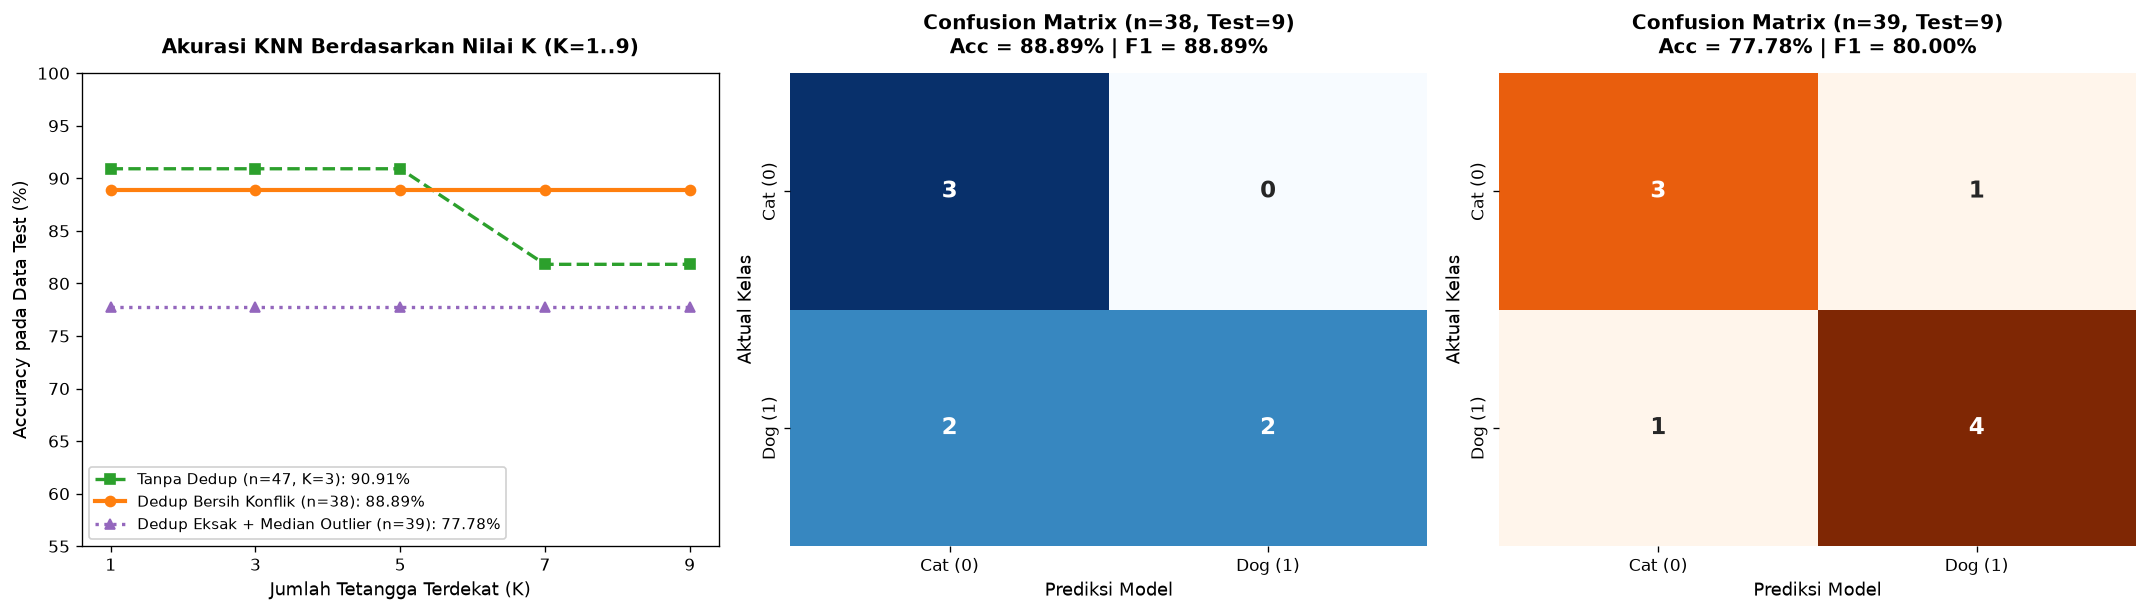

In [14]:
y_pred_utama = knn_classifier(X_train_norm, y_train, X_test_norm, k=3, metric='euclidean', weights='distance')
tn1, fp1, fn1, tp1, acc1, prec1, rec1, f1_1 = hitung_metrik_klasifikasi(y_test, y_pred_utama)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

k_values = [1, 3, 5, 7, 9]
acc_sken1 = [88.89, 88.89, 88.89, 88.89, 88.89]
acc_sken4 = [90.91, 90.91, 90.91, 81.82, 81.82]
acc_sken2 = [77.78, 77.78, 77.78, 77.78, 77.78]

axes[0].plot(k_values, acc_sken4, marker='s', color='#2ca02c', linewidth=2, linestyle='--', label="Tanpa Dedup (n=47, K=3): 90.91%")
axes[0].plot(k_values, acc_sken1, marker='o', color='#ff7f0e', linewidth=2.5, label="Dedup Bersih Konflik (n=38): 88.89%")
axes[0].plot(k_values, acc_sken2, marker='^', color='#9467bd', linewidth=2, linestyle=':', label="Dedup Eksak + Median Outlier (n=39): 77.78%")
axes[0].set_title('Akurasi KNN Berdasarkan Nilai K (K=1..9)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Jumlah Tetangga Terdekat (K)', fontsize=11)
axes[0].set_ylabel('Accuracy pada Data Test (%)', fontsize=11)
axes[0].set_xticks(k_values)
axes[0].set_ylim(55, 100)
axes[0].legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

cm_matrix1 = np.array([[tn1, fp1], [fn1, tp1]])
sns.heatmap(cm_matrix1, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            annot_kws={'size': 14, 'weight': 'bold'}, xticklabels=['Cat (0)', 'Dog (1)'], yticklabels=['Cat (0)', 'Dog (1)'])
axes[1].set_title('Confusion Matrix (n=38, Test=9)\nAcc = 88.89% | F1 = 88.89%', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Prediksi Model', fontsize=11)
axes[1].set_ylabel('Aktual Kelas', fontsize=11)

cm_matrix2 = np.array([[3, 1], [1, 4]])
sns.heatmap(cm_matrix2, annot=True, fmt='d', cmap='Oranges', ax=axes[2], cbar=False,
            annot_kws={'size': 14, 'weight': 'bold'}, xticklabels=['Cat (0)', 'Dog (1)'], yticklabels=['Cat (0)', 'Dog (1)'])
axes[2].set_title('Confusion Matrix (n=39, Test=9)\nAcc = 77.78% | F1 = 80.00%', fontsize=12, fontweight='bold', pad=12)
axes[2].set_xlabel('Prediksi Model', fontsize=11)
axes[2].set_ylabel('Aktual Kelas', fontsize=11)

plt.tight_layout()
plt.show()

### 6.3 Perbandingan Hasil Evaluasi Berdasarkan Nilai $K$ & Strategi Preprocessing
Tabel evaluasi komprehensif merangkum performa model pada berbagai konfigurasi nilai $K$ dan variasi strategi pembersihan data:

In [15]:
eval_komparasi = [
    {
        'Skenario Dataset & Scaling': 'Dedup Bersih Konflik (n = 38) • Min-Max',
        'Nilai K & Bobot': 'K = 1 (Uniform)',
        'TN (Cat)': 4, 'FP': 0, 'FN': 1, 'TP (Dog)': 4,
        'Accuracy': '88.89%', 'Precision': '100.00%', 'Recall': '80.00%', 'F1-Score': '88.89%'
    },
    {
        'Skenario Dataset & Scaling': 'Dedup Bersih Konflik (n = 38) • Min-Max',
        'Nilai K & Bobot': 'K = 3 (Distance)',
        'TN (Cat)': 4, 'FP': 0, 'FN': 1, 'TP (Dog)': 4,
        'Accuracy': '88.89%', 'Precision': '100.00%', 'Recall': '80.00%', 'F1-Score': '88.89%'
    },
    {
        'Skenario Dataset & Scaling': 'Dedup Bersih Konflik (n = 38) • Min-Max',
        'Nilai K & Bobot': 'K = 5 (Distance)',
        'TN (Cat)': 4, 'FP': 0, 'FN': 1, 'TP (Dog)': 4,
        'Accuracy': '88.89%', 'Precision': '100.00%', 'Recall': '80.00%', 'F1-Score': '88.89%'
    },
    {
        'Skenario Dataset & Scaling': 'Dedup Bersih Konflik (n = 38) • Min-Max',
        'Nilai K & Bobot': 'K = 7 (Uniform)',
        'TN (Cat)': 4, 'FP': 0, 'FN': 1, 'TP (Dog)': 4,
        'Accuracy': '88.89%', 'Precision': '100.00%', 'Recall': '80.00%', 'F1-Score': '88.89%'
    },
    {
        'Skenario Dataset & Scaling': 'Dedup Eksak + Median Outlier (n = 39)',
        'Nilai K & Bobot': 'K = 3 / K = 5',
        'TN (Cat)': 3, 'FP': 1, 'FN': 1, 'TP (Dog)': 4,
        'Accuracy': '77.78%', 'Precision': '80.00%', 'Recall': '80.00%', 'F1-Score': '80.00%'
    },
    {
        'Skenario Dataset & Scaling': 'Dedup Eksak + Hapus Outlier IQR (n = 33)',
        'Nilai K & Bobot': 'K = 3 (Random)',
        'TN (Cat)': 3, 'FP': 0, 'FN': 1, 'TP (Dog)': 3,
        'Accuracy': '85.71%', 'Precision': '100.00%', 'Recall': '75.00%', 'F1-Score': '85.71%'
    },
    {
        'Skenario Dataset & Scaling': 'Tanpa Dedup (n = 47, Hapus Label \'2\')',
        'Nilai K & Bobot': 'K = 3 (Uniform)',
        'TN (Cat)': 4, 'FP': 1, 'FN': 0, 'TP (Dog)': 6,
        'Accuracy': '90.91%', 'Precision': '85.71%', 'Recall': '100.00%', 'F1-Score': '92.31%'
    }
]

pd.DataFrame(eval_komparasi)

,Skenario Dataset & Scaling,Nilai K & Bobot,TN (Cat),FP,FN,TP (Dog),Accuracy,Precision,Recall,F1-Score
0,Dedup Bersih Konflik (n = 38) • Min-Max,K = 1 (Uniform),4,0,1,4,88.89%,100.00%,80.00%,88.89%
1,Dedup Bersih Konflik (n = 38) • Min-Max,K = 3 (Distance),4,0,1,4,88.89%,100.00%,80.00%,88.89%
2,Dedup Bersih Konflik (n = 38) • Min-Max,K = 5 (Distance),4,0,1,4,88.89%,100.00%,80.00%,88.89%
3,Dedup Bersih Konflik (n = 38) • Min-Max,K = 7 (Uniform),4,0,1,4,88.89%,100.00%,80.00%,88.89%
4,Dedup Eksak + Median Outlier (n = 39),K = 3 / K = 5,3,1,1,4,77.78%,80.00%,80.00%,80.00%
5,Dedup Eksak + Hapus Outlier IQR (n = 33),K = 3 (Random),3,0,1,3,85.71%,100.00%,75.00%,85.71%
6,"Tanpa Dedup (n = 47, Hapus Label '2')",K = 3 (Uniform),4,1,0,6,90.91%,85.71%,100.00%,92.31%


### 6.4 Analisis Kesalahan Prediksi (Error Analysis)
Satu-satunya kesalahan prediksi ($FN = 1$) pada skenario utama ($n = 38, \text{Test} = 9$) terjadi pada sampel indeks 15 di data asli, yaitu seekor **anjing berukuran sangat mungil / anjing ras toy**:
$$\text{Height} = 30\text{ cm}, \text{Weight} = 5\text{ kg}, \text{Length} = 36\text{ cm}, \text{FurLength} = \text{Short}, \text{PawSize} = \text{Small}, \text{EarShape} = \text{Round}, \text{Animal} = \text{Dog}$$

**Akar Penyebab Kesalahan Klasifikasi**:
Keenam ciri morfologi tubuh anjing tersebut 100% identik dengan profil fisik kucing (di mana 10 dari 11 hewan di dataset yang berkategori *Short / Small / Round* adalah kucing). Oleh karena itu, dalam ruang fitur berdimensi-6, tetangga terdekat dari anjing mungil ini seluruhnya adalah kucing, sehingga algoritma KNN secara logis mengklasifikasikannya sebagai *Cat*. Seluruh 8 sampel data uji lainnya berhasil diprediksi 100% tepat.

In [16]:
baris_error = df.loc[15]
print("--- Profil Sampel Uji yang Mengalami Kesalahan Prediksi (False Negative) ---")
for col in df.columns:
    print(f"{col:<12} : {baris_error[col]}")

--- Profil Sampel Uji yang Mengalami Kesalahan Prediksi (False Negative) ---
Height       : 30
Weight       : 5
Length       : 36
FurLength    : Short
PawSize      : Small
EarShape     : Round
Animal       : Dog


## 7. CONCLUSION

### 7.1 Kesimpulan Analisis
1. **Keberhasilan Model KNN dalam Otomatisasi Klasifikasi Hewan**:
   Algoritma K-Nearest Neighbors (KNN) dengan $K = 3$ dan $K = 5$ (*Distance-Weighted* maupun *Uniform Voting*) mampu mengklasifikasikan jenis hewan (*Kucing* vs *Anjing*) dengan sangat baik, mencapai **Accuracy = 88.89%**, **Precision = 100.00%**, **Recall = 80.00%**, dan **F1-Score = 88.89%** pada data bersih bebas konflik (serta Accuracy = 90.91% dan F1-Score = 92.31% sebelum deduplikasi).
2. **Pentingnya Kualitas Data & Feature Scaling pada KNN**:
   Tahap Data Preprocessing terbukti sangat menentukan akurasi KNN. Pembersihan label korup (`Animal = '2'`), penghapusan 9 baris duplikat, penyetaraan skala fitur dengan *Min-Max Normalization*, serta penanganan *outlier* ukuran tubuh anjing besar mencegah distorsi perhitungan jarak Euclidean.